<a href="https://colab.research.google.com/github/hristinagjorgjievska/Natural-Language-Processing/blob/master/lab1/laboratory_exercise_1_transformers_based_models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Задача 1: За даденото податочно множество да се креираат Word2Vec SkipGram
- Имаме податочно множество Sarcasm содржи со сарказам и нивни неутрални верзии. Целта е да се класифицира дали реченицата има сарказам.
- Бидејќи моделите работат само со броеви, прв чекор е секој збор да се претвори во вектор.

## Зошто вектори и зошто баш Word2Vec
- Наједноставен начин е one-hot: секој збор е вектор долг колку целиот речник, со единица на една позиција и нули на сите други.
  - Проблем 1: Векторите се огромни (илјадници димензии и скоро сите се 0).
  - Проблем 2: good и great се исто различни колку good и tablе па така моделот не гледа никаква сличност меѓу зборовите.

## Како Word2Vec ги учи векторите
- Невронска мрежа со еден скриен слој кој решава помошна задача: предвидување на соседните зборови. Самото предвидување не ни треба, туку тежините што мрежата ги научува при тоа.

| | Влез | Излез | `sg` |
|---|---|---|---|
| **CBOW** | контекстот (соседните зборови) | централниот збор | `sg=0` |
| **SkipGram** | централниот збор | секој збор од контекстот | `sg=1` |

- Задачата бара да се искористи SkipGram, иако е побавен подобро учи ретки зборови и подобар е за мали множества.
- Контекстот 3 (window=3) значи до 3 збора на лево и 3 збора на десно од централниот.
- Пример: *'i just love waiting in line for hours'* со централен збор waiting:

  - **[i  just  love]** waiting **[in  line  for]** hours

**- SkipGram од ова прави 6 парови за тренирање: **
  1. (waiting -> i)
  2. (waiting -> just)
  3. (waiting -> love)
  4. (waiting -> in)
  5. (waiting -> line)
  6. (waiting -> for)

**- Од каде доаѓаат векторите?**
  - Скриениот слој е матрица со големина (број на зборови во речникот х 50).
  - Секој ред од неа е векторот на еден збор.
  - Мрежата ги поместува тие редови така што зборот добро ги предвидува своите соседи.
  - Затоа зборовите со исти соседи завршуваат со слични редови (слични вектори).

- **Дополнување**: предвидувањето на целиот речник е скапо, затоа gensim стандардно користи negative sampling. Наместо ,,кој од сите зборови е сосед?", мрежата учи да разликува вистински сосед од 5 случајни зборови.

| Параметар | Вредност | Значење |
|---|---|---|
| `vector_size` | 50 | должина на векторот за секој збор |
| `window` | 3 | контекст 3  |
| `sg` | 1 | SkipGram  |
| `min_count` | 5 | зборовите со помалку од 5 појавувања се игнорираат, бидејќи од 1–2 примери не може да се научи добар вектор |

In [4]:
!pip install gensim

In [5]:
import pandas as pd
from gensim.models import Word2Vec
import nltk
from nltk.tokenize import word_tokenize
nltk.download('punkt_tab') # модел што word_tokenize го користи за да знае каде да ги дели речениците

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [6]:
data = pd.read_csv('sarcasm.txt', sep='\t')

In [7]:
data

,Style 1,Style 2
0,The only thing I got from college is a caffein...,"College is really difficult, expensive, tiring..."
1,Remember the hundred emails from companies whe...,"I, at the bare minimum, wish companies actuall..."
2,Today my pop-pop told me I was not “forced” to...,"Today my pop-pop told me I was not ""forced"" to..."
3,@VolphanCarol @littlewhitty @mysticalmanatee I...,I would say Ted Cruz is an asshole and doesn’t...
4,Why would Alexa's recipe for Yorkshire pudding...,Great recipe from Alexa
...,...,...
688,"wow, ok, unfollowing now. Was a big fan of put...","I enjoy dancing the hokey cokey, in particular..."
689,Only posting selfie’s?? On YOUR own Instagram ...,It's my Instagram for a reason why wouldn't it...
690,do people with clear skin feel accomplished?? ...,people with clear skin are more comfortable in...
691,Update: holding hands with your mom and walkin...,Holding hands with your parent while walking a...


In [8]:
data['Tokens 1'] = data['Style 1'].str.lower().apply(word_tokenize)
data['Tokens 2'] = data['Style 2'].str.lower().apply(word_tokenize)

In [9]:
sentences = data['Tokens 1'].tolist() + data['Tokens 2'].tolist()

**1. Тренирање**
- Тука е учењето на моделот. Word2Vec поминува низ сите 1368 реченици, со window од 3 збора лево и десно и за секој збор што се појавува барем 5 пати учи 50 броеви. **Резултатот е објектот word2vec_model**. <br>

2.** .wv **
- wv значи word vectors: делот од моделот каде што се чуваат научените вектори.

3. words и word_vectors: две листи што одат паралелно
  - words - word2vec_model.wv.index_to_key е листа од зборовите во речникот, подредени по честота
  - word_vectors = word2vec.wv.vectors е матрица од 4450 реда и 50 колони (секој ред е векторот на еден збор)

  - **поврзани се преку позицијата**: зборот words[i] го има векторот word_vectors[i].

In [10]:
word2vec_model = Word2Vec(sentences, vector_size=50, window=3, min_count=1, sg=1)
words = word2vec_model.wv.index_to_key
word_vectors = word2vec_model.wv.vectors

In [11]:
print(words[:10])
print(len(words))
print(word_vectors.shape)

['i', '.', 'the', 'to', 'a', 'and', ',', 'my', 'is', '’']
4455
(4455, 50)


===========================================================================

# Задача 2: Визуелизација на првите 10 зборови од секоја класа

### Треба:
    - За секоја класа (саркастична и неутрална) да избереме 10 зборови
    - Да ги нацртаме со користење на векторите од Задача 1

In [12]:
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

In [13]:
words_style_1 = data['Tokens 1'].explode().value_counts().index[:10].tolist()
words_style_2 = data['Tokens 2'].explode().value_counts().index[:10].tolist()

In [14]:
tsne = TSNE(n_components=2, perplexity=5)
word_vectors_2d = tsne.fit_transform(word2vec_model.wv[words_style_1 + words_style_2])

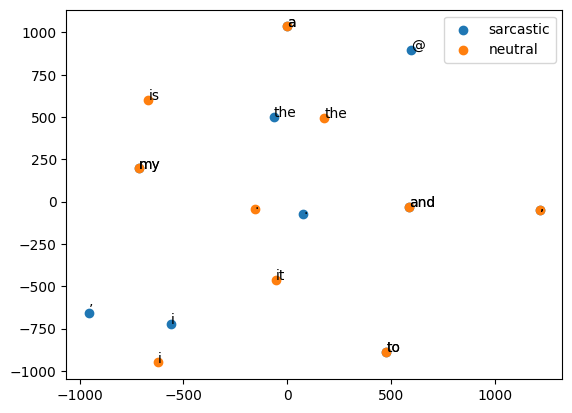

In [15]:
plt.scatter(word_vectors_2d[:10, 0], word_vectors_2d[:10, 1], label='sarcastic')
plt.scatter(word_vectors_2d[10:, 0], word_vectors_2d[10:, 1], label='neutral')
for label, x, y in zip(words_style_1 + words_style_2, word_vectors_2d[:, 0], word_vectors_2d[:, 1]):
    plt.annotate(label, xy=(x, y), xytext=(0, 0), textcoords='offset points')
plt.legend()
plt.show()

# Задача 3: За секоја реченица да се креира векторска репрезентација добиена како вектор од минималните вредности по секоја димензија на векторите на нејзините составни зборови
- Секоја реченица да стане еден вектор
- За секој од 50-те позиции ја земаме најмалата бројка меѓу зборовите

In [16]:
import numpy as np

In [17]:
sentence_vectors = []
for sentence in sentences:
    sentence_vectors.append(np.min(word2vec_model.wv[sentence], axis=0))

In [18]:
print(len(sentence_vectors))
print(sentence_vectors[0])

1386
[ 6.3972948e-03 -1.5664902e-02 -1.5979265e-01  1.7331317e-02
 -2.2368933e-01 -2.1590416e-01  1.7635679e-02  4.7658712e-02
 -3.0249330e-01 -3.3163399e-01 -5.9243233e-04 -4.7947454e-01
  2.6206288e-02  1.8852917e-02 -9.6832834e-02  2.5532747e-02
  2.3355426e-02 -1.3095981e-01 -6.8371236e-01 -2.5970683e-01
  2.7580461e-03  3.6330257e-02  3.3379979e-02 -2.0357578e-01
 -1.0486284e-02  1.1258090e-02 -2.0372762e-01 -6.2606982e-03
 -3.7046883e-01  2.1025505e-02 -2.8344685e-02 -1.8240196e-01
  1.5467978e-02 -2.1210004e-01 -3.3830252e-01  4.9953940e-03
  2.7335130e-02  3.0661733e-03  2.2267316e-02 -1.6328761e-01
  1.5465211e-02 -1.3405408e-01 -1.3771856e-01 -8.1084199e-02
  3.8797259e-02 -4.9487777e-02 -1.0167130e-01 -3.4215027e-01
  1.3323685e-02  1.9694749e-02]


# Задача 4: Даденото податочно множество да се подели на подмножества за тренирање, валидација и тестирање во сооднос 70:15:15.

In [19]:
train_size = int(0.7 * len(data))
val_size = int(0.15 * len(data))

In [20]:
train_data = data[:train_size]
val_data = data[train_size:train_size + val_size]
test_data = data[train_size + val_size:]

In [21]:
len(train_data), len(val_data), len(test_data)

(485, 103, 105)

In [22]:
sarcastic_vectors = sentence_vectors[:len(data)]
neutral_vectors = sentence_vectors[len(data):]

In [23]:
train_vectors = sarcastic_vectors[:train_size] + neutral_vectors[:train_size]
val_vectors = sarcastic_vectors[train_size:train_size + val_size] + neutral_vectors[train_size:train_size + val_size]
test_vectors = sarcastic_vectors[train_size + val_size:] + neutral_vectors[train_size + val_size:]

In [24]:
train_labels = [1] * len(train_data) + [0] * len(train_data)
val_labels = [1] * len(val_data) + [0] * len(val_data)
test_labels = [1] * len(test_data) + [0] * len(test_data)

# Задача 5: Да се тренира и евалуира дрво на одлука за класификација на речениците од податочното множество за тоа дали содржат сарказам или не врз основа на векторските репрезентации добиени во чекор 3), користејќи ја поделбата на подмножества за тренирање, валидација и тестирање од чекор 4)

In [25]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report

In [26]:
tree = DecisionTreeClassifier(max_depth=5)
tree.fit(train_vectors, train_labels)

DecisionTreeClassifier(max_depth=5)

In [27]:
print(classification_report(val_labels, tree.predict(val_vectors)))

              precision    recall  f1-score   support

           0       0.71      0.73      0.72       103
           1       0.72      0.70      0.71       103

    accuracy                           0.71       206
   macro avg       0.71      0.71      0.71       206
weighted avg       0.71      0.71      0.71       206



In [28]:
print(classification_report(test_labels, tree.predict(test_vectors)))

              precision    recall  f1-score   support

           0       0.71      0.82      0.76       105
           1       0.79      0.67      0.72       105

    accuracy                           0.74       210
   macro avg       0.75      0.74      0.74       210
weighted avg       0.75      0.74      0.74       210



# Задача 6: Да се тренира и евалуира моделот BERT за класификација на речениците од податочното множество за тоа дали содржат сарказам или не користејќи јаподелбата на подмножества за тренирање, валидација и тестирање од чекор 4)

In [29]:
import torch
from torch.utils.data import Dataset
from transformers import AutoModelForSequenceClassification, AutoTokenizer, TrainingArguments, Trainer

In [30]:
model_name = 'bert-base-uncased'
lr = 0.00001
epochs = 5
wd = 0.005

In [31]:
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2)
training_args = TrainingArguments(output_dir='out/', report_to='none', learning_rate=lr,
                                  num_train_epochs=epochs, weight_decay=wd,
                                  eval_strategy='epoch',
                                  save_strategy='no')

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [32]:
class SarcasmDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)

In [33]:
train_texts = train_data['Style 1'].tolist() + train_data['Style 2'].tolist()
val_texts = val_data['Style 1'].tolist() + val_data['Style 2'].tolist()
test_texts = test_data['Style 1'].tolist() + test_data['Style 2'].tolist()

In [34]:
train_dataset = SarcasmDataset(tokenizer(train_texts), train_labels)
val_dataset = SarcasmDataset(tokenizer(val_texts), val_labels)
test_dataset = SarcasmDataset(tokenizer(test_texts), test_labels)

In [35]:
trainer = Trainer(model=model, args=training_args,
                  train_dataset=train_dataset, eval_dataset=val_dataset,
                  processing_class=tokenizer)

In [36]:
trainer.train()

Epoch,Training Loss,Validation Loss
1,No log,0.374798
2,No log,0.355897
3,No log,0.428423
4,No log,0.437872
5,0.271767,0.468936


TrainOutput(global_step=610, training_loss=0.24334493386940878, metrics={'train_runtime': 79.8174, 'train_samples_per_second': 60.764, 'train_steps_per_second': 7.642, 'total_flos': 113817114771960.0, 'train_loss': 0.24334493386940878, 'epoch': 5.0})

In [37]:
predictions = trainer.predict(test_dataset)
print(classification_report(test_labels, predictions.predictions.argmax(axis=1)))

              precision    recall  f1-score   support

           0       0.84      0.92      0.88       105
           1       0.91      0.82      0.86       105

    accuracy                           0.87       210
   macro avg       0.88      0.87      0.87       210
weighted avg       0.88      0.87      0.87       210

